In [93]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.lines import Line2D
import matplotlib as mpl
from matplotlib.patches import PathPatch, Rectangle
from matplotlib.path import Path as MplPath
from itertools import chain
from project_settings import PATH_WRK, BASE, METRIC, YEARS, SRC_DIR, RESULTS_DIR, RUN_DIR


# Chemin racine du projet (à adapter si besoin)
OUTPUT_LOOP_DIR = Path(SRC_DIR)   # results of the run chosen in project_settings (RD_UNIT, DIMENSION, TECH)
GRAPHS_DIR = Path(RESULTS_DIR) / "graphs_output"   # ou les PNG seront sauvegardes
GRAPHS_DIR.mkdir(parents=True, exist_ok=True)


def _savefig_safe(fig, path, **kwargs):
    """Comme fig.savefig(path, **kwargs), mais si le fichier est verrouille (ex. ouvert
    dans une visionneuse Windows), retente sous un nom alternatif au lieu de planter."""
    path = Path(path)
    try:
        fig.savefig(path, **kwargs)
        return path
    except OSError as exc:
        alt_path = path.with_stem(path.stem + "_new")
        print(f"Impossible d'ecrire {path.name} ({exc}) -> sauvegarde sous {alt_path.name}")
        fig.savefig(alt_path, **kwargs)
        return alt_path


In [94]:
# Pour chaque prefixe de metrique : (header, index_col) a passer a pd.read_csv
LAYOUTS = {
    "rd_dir_CI":     dict(header=[0, 1, 2], index_col=[0, 1, 2]),   # EXIOBASE / FIGARO / OECD_ICIO / GTAP
    "rd_embod_CI":   dict(header=[0, 1, 2], index_col=[0, 1, 2]),
    "rd_imp_CI":     dict(header=[0, 1, 2], index_col=[0, 1, 2]),
    "rd_dir_CAPITAL":    dict(header=[0, 1, 2], index_col=[0, 1, 2]),   # CAPITAL
    "rd_embod_CAPITAL":  dict(header=[0, 1, 2], index_col=[0, 1, 2]),
    "rd_dir_cit":    dict(header=[0, 1],    index_col=[0, 1, 2]),   # Patents_Citation (index = Year, Region, Sector)
    "rd_dir_fdips":  dict(header=0,         index_col=[0, 1]),      # FDI (colonnes = Region seule)
}


def _match_layout(filename: str):
    """Trouve le prefixe de metrique (le plus long) qui matche le nom de fichier."""
    stem = filename.removesuffix(".csv")
    candidates = [prefix for prefix in LAYOUTS if stem.startswith(prefix + "_")]
    if not candidates:
        raise ValueError(f"Aucun layout connu pour {filename!r}")
    return max(candidates, key=len)


def load_matrix(path: Path) -> pd.DataFrame:
    """Charge un fichier SRDQ (c,s) en DataFrame bilateral (index = origine, colonnes = destination)."""
    layout = LAYOUTS[_match_layout(path.name)]
    df = pd.read_csv(path, sep=";", **layout)
    return df


In [95]:
_FOLDER_RE = re.compile(r"output_loop_(?P<base>.+)_(?P<year>\d{4})$")


def discover_files(output_loop_dir: Path = OUTPUT_LOOP_DIR):
    rows = []
    for base_dir in sorted(output_loop_dir.iterdir()):
        if not base_dir.is_dir():
            continue
        for year_dir in sorted(base_dir.iterdir()):
            m = _FOLDER_RE.match(year_dir.name)
            if not m or not year_dir.is_dir():
                continue
            year = int(m.group("year"))
            for csv_path in sorted(year_dir.glob("*.csv")):
                try:
                    metric = _match_layout(csv_path.name)
                except ValueError:
                    continue
                rows.append({
                    "base": base_dir.name,
                    "year": year,
                    "metric": metric,
                    "path": csv_path,
                })
    return pd.DataFrame(rows)


catalog = discover_files()
catalog


,base,year,metric,path
0,CAPITAL,1995,rd_dir_CAPITAL,"D:\ENTICE\rendu_fin_stage\SRDQ (c,s)\CAPITAL\o..."
1,CAPITAL,1995,rd_dir_CAPITAL,"D:\ENTICE\rendu_fin_stage\SRDQ (c,s)\CAPITAL\o..."
2,CAPITAL,1995,rd_embod_CAPITAL,"D:\ENTICE\rendu_fin_stage\SRDQ (c,s)\CAPITAL\o..."
3,CAPITAL,1995,rd_embod_CAPITAL,"D:\ENTICE\rendu_fin_stage\SRDQ (c,s)\CAPITAL\o..."
4,CAPITAL,1996,rd_dir_CAPITAL,"D:\ENTICE\rendu_fin_stage\SRDQ (c,s)\CAPITAL\o..."
...,...,...,...,...
611,Patents_Citation,2020,rd_dir_cit,"D:\ENTICE\rendu_fin_stage\SRDQ (c,s)\Patents_C..."
612,Patents_Citation,2021,rd_dir_cit,"D:\ENTICE\rendu_fin_stage\SRDQ (c,s)\Patents_C..."
613,Patents_Citation,2021,rd_dir_cit,"D:\ENTICE\rendu_fin_stage\SRDQ (c,s)\Patents_C..."
614,Patents_Citation,2022,rd_dir_cit,"D:\ENTICE\rendu_fin_stage\SRDQ (c,s)\Patents_C..."


In [96]:
def origin_totals(df: pd.DataFrame) -> pd.Series:
    s = df.sum(axis=1)
    if isinstance(df.index, pd.MultiIndex) and "Region" in df.index.names:
        s = s.groupby(level="Region").sum()
    return s.sort_values(ascending=False)


def destination_totals(df: pd.DataFrame) -> pd.Series:
    s = df.sum(axis=0)
    if isinstance(df.columns, pd.MultiIndex) and "Region" in df.columns.names:
        s = s.groupby(level="Region").sum()
    return s.sort_values(ascending=False)


In [97]:
REGION_TO_8R = {
    # Europe au sens large (UE + Suisse/Norvege/UK/Balkans), comme dans agg_FIGARO2_8R.xlsx
    "AT": "EU", "BE": "EU", "BG": "EU", "CY": "EU", "CZ": "EU", "DE": "EU", "DK": "EU",
    "EE": "EU", "ES": "EU", "FI": "EU", "FR": "EU", "GR": "EU", "HR": "EU", "HU": "EU",
    "IE": "EU", "IT": "EU", "LT": "EU", "LU": "EU", "LV": "EU", "MT": "EU", "NL": "EU",
    "PL": "EU", "PT": "EU", "RO": "EU", "SE": "EU", "SI": "EU", "SK": "EU",
    "CH": "EU", "NO": "EU", "UK": "EU", "IS": "EU",
    # Grandes zones individuelles
    "US": "US", "CA": "CA", "JP": "JP", "KR": "KR", "CN": "CN", "IN": "IN",
    # Reste du monde (tout le reste, y compris le code "RW" deja present dans les donnees)
    "AU": "RW", "BR": "RW", "MX": "RW", "RU": "RW", "RW": "RW", "TW": "RW",
    "SG": "RW", "IL": "RW", "CL": "RW", "ZA": "RW", "AR": "RW", "ID": "RW", "SA": "RW", "TR": "RW",
}
REGION_8R_ORDER = ["US", "CA", "EU", "JP", "KR", "CN", "IN", "RW"]


def _sector_level_name(names):
    """Le code secteur est sous 'Item' (familles EXIOBASE/FIGARO/OECD/GTAP/CAPITAL) ou 'Sector' (Patents_Citation/FDI)."""
    if "Item" in names:
        return "Item"
    if "Sector" in names:
        return "Sector"
    return None


def _region_8r_index(idx):
    """Renvoie les labels 8R (Index simple) correspondant a un axe (MultiIndex ou Index simple)."""
    if isinstance(idx, pd.MultiIndex) and "Region" in idx.names:
        values = idx.get_level_values("Region")
    else:
        values = pd.Index(idx)
    return values.map(REGION_TO_8R)


def aggregate_to_8r(df: pd.DataFrame) -> pd.DataFrame:
    """Regroupe une matrice bilaterale (Region present sur les deux axes) en 8 macro-regions."""
    row_region = _region_8r_index(df.index)
    col_region = _region_8r_index(df.columns)

    grouped = df.groupby(row_region).sum()          # regroupe les lignes (origine)
    grouped = grouped.T.groupby(col_region).sum().T  # regroupe les colonnes (destination)
    return grouped.reindex(index=REGION_8R_ORDER, columns=REGION_8R_ORDER)


In [98]:
def list_sectors(base: str, metric: str, year: int, catalog: pd.DataFrame = catalog) -> list:
    """Liste les codes secteur ('Item' ou 'Sector') disponibles pour une base/metrique/annee.
    Utile car la nomenclature des secteurs varie selon la base (ex. EXIOBASE/CAPITAL utilisent
    'C29_C30' combine, alors qu'un autre mapping pourrait avoir 'C29' seul)."""
    row = catalog[(catalog.base == base) & (catalog.year == year) & (catalog.metric == metric)]
    if row.empty:
        raise ValueError(f"Pas de fichier pour {base}/{metric}/{year}")
    df = load_matrix(row.iloc[0]["path"])
    level = _sector_level_name(df.columns.names) if isinstance(df.columns, pd.MultiIndex) else None
    if level is None:
        return sorted(set(df.columns.astype(str)))
    return sorted(set(df.columns.get_level_values(level)))


_LEVEL_LABELS = {"country_sector": "pays x secteur", "country": "pays", "sector": "secteur"}

_METRIC_LABELS = {
    "rd_dir_CI": "consommation intermediaire directe",
    "rd_embod_CI": "contenu total incorpore (direct + indirect)",
    "rd_imp_CI": "R&D importee",
    "rd_dir_CAPITAL": "consommation de capital fixe (directe)",
    "rd_embod_CAPITAL": "consommation de capital fixe (incorporee)",
    "rd_dir_cit": "citations de brevets",
    "rd_dir_fdips": "investissements directs etrangers (FDI)",
}


def _build_palette(n: int) -> list:
    palettes = list(chain(plt.cm.tab20.colors, plt.cm.Set3.colors, plt.cm.Dark2.colors))
    if n > len(palettes):
        palettes *= int(np.ceil(n / len(palettes)))
    return palettes[:n]


def _axis_labels(index, level: str, region_map: dict = None) -> pd.Index:
    """Construit les labels d'un axe (lignes ou colonnes) selon le niveau de detail demande."""
    is_multi = isinstance(index, pd.MultiIndex) and "Region" in index.names
    region = index.get_level_values("Region") if is_multi else pd.Index(index)
    if region_map is not None:
        region = pd.Index(region).map(region_map)

    sector_name = _sector_level_name(index.names) if is_multi else None
    sector = index.get_level_values(sector_name) if sector_name else None

    if level == "country_sector":
        if sector is None:
            raise ValueError("Pas de niveau secteur disponible sur cet axe pour level='country_sector'.")
        return pd.Index(pd.Index(region).astype(str) + "-" + pd.Index(sector).astype(str))
    elif level == "country":
        return pd.Index(region).astype(str)
    elif level == "sector":
        if sector is None:
            raise ValueError("Pas de niveau secteur disponible sur cet axe pour level='sector'.")
        return pd.Index(sector).astype(str)
    else:
        raise ValueError("level doit etre 'country_sector', 'country' ou 'sector'")


def _filter_axis_mask(index, country: str = None, sector: str = None):
    """Masque booleen sur un axe : filtre par pays (MultiIndex avec 'Region', ou Index plat
    de codes pays) et/ou par secteur (necessite un niveau secteur). None = pas de filtre."""
    n = len(index)
    mask = np.ones(n, dtype=bool)

    if country is not None:
        if isinstance(index, pd.MultiIndex) and "Region" in index.names:
            mask &= (index.get_level_values("Region") == country)
        elif not isinstance(index, pd.MultiIndex):
            mask &= (pd.Index(index).astype(str) == country)
        else:
            raise ValueError("Cet axe n'a pas de niveau 'Region' pour filtrer par pays.")

    if sector is not None:
        sector_name = _sector_level_name(index.names) if isinstance(index, pd.MultiIndex) else None
        if sector_name is None:
            raise ValueError("Cet axe n'a pas de niveau secteur pour filtrer.")
        mask &= (index.get_level_values(sector_name) == sector)

    return mask


def _describe_axis(level: str, country: str = None, sector: str = None) -> str:
    label = _LEVEL_LABELS[level]
    restrictions = [v for v in (country, sector) if v is not None]
    if restrictions:
        label += " (" + ", ".join(restrictions) + " only)"
    return label


def plot_flow_sankey_full(base: str, metric: str, year: int,
                           origin_level: str = "country_sector", dest_level: str = "country_sector",
                           origin_country: str = None, origin_sector: str = None,
                           dest_country: str = None, dest_sector: str = None,
                           origin_region_map: dict = None, dest_region_map: dict = None,
                           top_n: int = 25,
                           figsize: tuple = (18, 12), node_margin: float = 0.005,
                           left_x: float = 0.15, right_x: float = 0.85,
                           title: str = None, save_name: str = None, catalog: pd.DataFrame = catalog):
    """"Curved ribbon" flow diagram, entierement parametrable.

    origin_level / dest_level : "country", "sector" ou "country_sector".
    origin_country / origin_sector / dest_country / dest_sector : filtre optionnel
        (None = garde tout) independant de chaque cote.
    top_n : garde les N plus gros FLUX individuels, APRES filtrage, tous cotes confondus
        (None = tous les flux positifs).

    Cas FDI : dans le fichier brut, les lignes sont (host, sector) = ou atterrit
    l'investissement, et les colonnes sont juste le pays source (investisseur, sans
    secteur). On transpose automatiquement pour retrouver la convention habituelle
    (origine = investisseur, destination = pays+secteur receveur) ; origin_level est
    alors force a 'country' puisque le secteur de l'investisseur n'existe pas.
    """
    row = catalog[(catalog.base == base) & (catalog.year == year) & (catalog.metric == metric)]
    if row.empty:
        raise ValueError(f"No file for {base}/{metric}/{year}")
    df = load_matrix(row.iloc[0]["path"])

    if base == "FDI":
        df = df.T   # <-- lignes/colonnes brutes inversees pour FDI, cf. docstring
        if origin_level != "country":
            print(f"FDI: pas de secteur cote origine (investisseur) -> origin_level force a 'country' (etait {origin_level!r}).")
            origin_level = "country"
        if origin_sector is not None:
            print(f"FDI: pas de secteur cote origine -> origin_sector={origin_sector!r} ignore.")
            origin_sector = None

    row_mask = _filter_axis_mask(df.index, origin_country, origin_sector)
    col_mask = _filter_axis_mask(df.columns, dest_country, dest_sector)
    df = df.loc[row_mask, col_mask]
    if df.empty:
        raise ValueError(
            f"Aucune donnee apres filtrage (origin_country={origin_country!r}, "
            f"origin_sector={origin_sector!r}, dest_country={dest_country!r}, dest_sector={dest_sector!r})."
        )

    origin_labels = _axis_labels(df.index, origin_level, region_map=origin_region_map)
    dest_labels = _axis_labels(df.columns, dest_level, region_map=dest_region_map)

    flows = pd.DataFrame(df.values, index=origin_labels, columns=dest_labels)
    flows = flows.groupby(level=0).sum()
    flows = flows.T.groupby(level=0).sum().T

    long = flows.stack()
    long.index = long.index.set_names(["source", "target"])
    long = long[long > 0].sort_values(ascending=False)
    if top_n is not None:
        long = long.head(top_n)   # top-N flux, deja filtres
    if long.empty:
        raise ValueError("No positive flow to display with these parameters.")

    links = long.reset_index(name="value")
    total = links["value"].sum()
    links["share"] = links["value"] / total

    mpl.rcParams["font.family"] = "sans-serif"
    mpl.rcParams["font.sans-serif"] = ["Calibri", "DejaVu Sans"]
    mpl.rcParams["font.size"] = 11
    mpl.rcParams["axes.titlesize"] = 20
    mpl.rcParams["axes.titleweight"] = "bold"

    source_totals = links.groupby("source")["share"].sum().sort_values(ascending=False)
    target_totals = links.groupby("target")["share"].sum().sort_values(ascending=False)
    sources = source_totals.index.tolist()
    target_labels = target_totals.index.tolist()

    source_colors = dict(zip(sources, _build_palette(len(sources))))

    def compute_stacked_layout(totals, margin):
        n = len(totals)
        usable_height = 1 - margin * (n - 1)
        scale = usable_height / totals.sum()
        positions = {}
        y = 1
        for name, val in totals.items():
            h = val * scale
            y_low = y - h
            positions[name] = (y_low, y, (y + y_low) / 2, h)
            y = y_low - margin
        return positions, scale

    source_pos, source_scale = compute_stacked_layout(source_totals, node_margin)
    target_pos, target_scale = compute_stacked_layout(target_totals, node_margin)
    scale = min(source_scale, target_scale)
    source_offsets = {s: source_pos[s][0] for s in sources}
    target_offsets = {t: target_pos[t][0] for t in target_labels}

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.06)
    ax.axis("off")

    axis_title_style = dict(fontsize=18, fontweight="bold", color="black")
    ax.text(left_x, 1.03, "ORIGIN", ha="center", va="bottom", **axis_title_style)
    ax.text(right_x, 1.03, "DESTINATION", ha="center", va="bottom", **axis_title_style)
    ax.plot([left_x - 0.08, left_x + 0.08], [1.015, 1.015], lw=2, color="black")
    ax.plot([right_x - 0.08, right_x + 0.08], [1.015, 1.015], lw=2, color="black")

    label_fontsize = 9 if len(sources) > 25 else 10
    for s in sources:
        y_low, y_high, y_center, h = source_pos[s]
        ax.add_patch(Rectangle((left_x - 0.015, y_low), 0.02, h, color=source_colors[s], alpha=0.9))
        ax.text(left_x - 0.02, y_center, s, ha="right", va="center", fontsize=label_fontsize, color="black")

    target_fontsize = 9 if len(target_labels) > 25 else 12
    for t in target_labels:
        y_low, y_high, y_center, h = target_pos[t]
        ax.text(right_x + 0.01, y_center, t, ha="left", va="center",
                 fontsize=target_fontsize, fontweight="bold", color="black")

    def draw_flow(ax, x0, y0_low, y0_high, x1, y1_low, y1_high, color, alpha=0.55):
        verts = [
            (x0, y0_high), (0.5, y0_high), (0.5, y1_high), (x1, y1_high),
            (x1, y1_low), (0.5, y1_low), (0.5, y0_low), (x0, y0_low),
            (x0, y0_high),
        ]
        codes = [
            MplPath.MOVETO, MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4,
            MplPath.LINETO, MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4, MplPath.CLOSEPOLY,
        ]
        ax.add_patch(PathPatch(MplPath(verts, codes), facecolor=color, edgecolor="none", alpha=alpha))

    for _, r in links.iterrows():
        h = r["share"] * scale
        s, t = r["source"], r["target"]
        y0_low = source_offsets[s]; y0_high = y0_low + h; source_offsets[s] += h
        y1_low = target_offsets[t]; y1_high = y1_low + h; target_offsets[t] += h
        draw_flow(ax, left_x, y0_low, y0_high, right_x, y1_low, y1_high, source_colors[s])

    metric_label = _METRIC_LABELS.get(metric, metric)
    origin_desc = _describe_axis(origin_level, origin_country, origin_sector)
    dest_desc = _describe_axis(dest_level, dest_country, dest_sector)
    n_flows = len(links)
    flows_note = f"top {n_flows} flows" if top_n is not None else f"all positive flows ({n_flows})"

    auto_title = (
        f"R&D Flows - {base} {year} ({metric_label})\n"
        f"Origin: {origin_desc}  |  Destination: {dest_desc}  |  {flows_note}"
    )
    fig.suptitle(title or auto_title, fontsize=15, y=1.0)

    if save_name is None:
        def tag(level, country, sector):
            t = level
            if country: t += f"-{country}"
            if sector: t += f"-{sector}"
            return t
        save_name = (
            f"Sankey_{base}_{metric}_{year}_"
            f"{tag(origin_level, origin_country, origin_sector)}-to-"
            f"{tag(dest_level, dest_country, dest_sector)}_"
            f"{'top' + str(top_n) if top_n is not None else 'all'}"
        )
    _savefig_safe(fig, GRAPHS_DIR / f"{save_name}.png", dpi=300, bbox_inches="tight", facecolor="white")

    plt.show()
    return links

In [99]:
# plot_flow_sankey_full(BASE, METRIC, 2019,
#                        dest_level="country_sector", dest_sector="C29_C30",
#                        top_n=40)

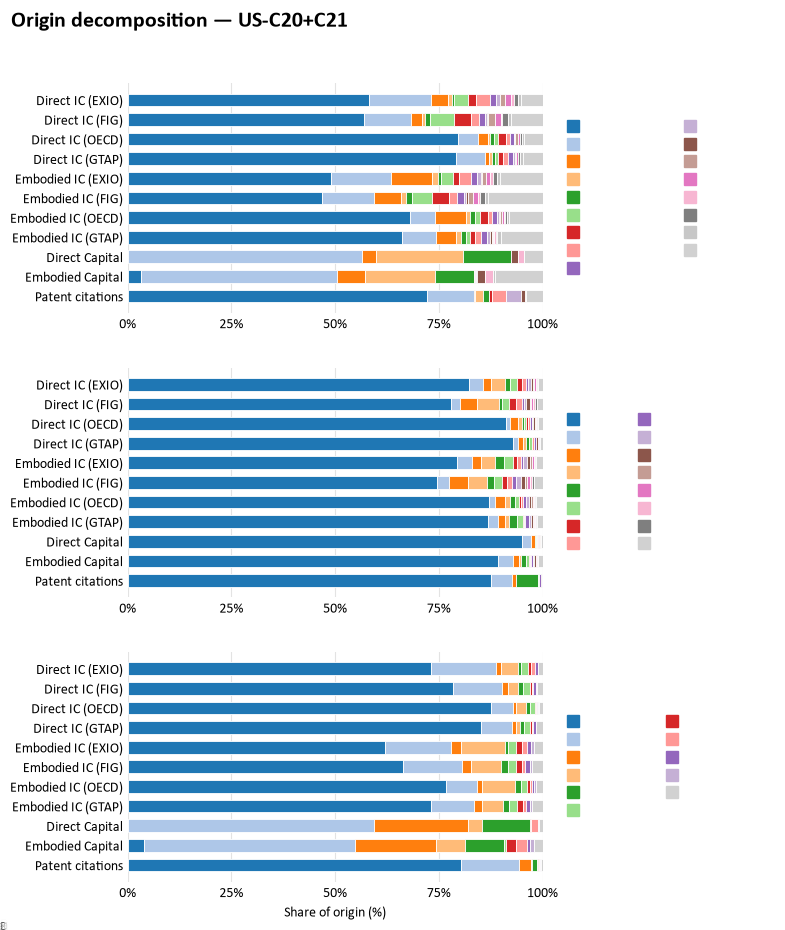

In [100]:
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Calibri", "Carlito", "DejaVu Sans"]

TOP_N_DEFAULT = {"country_sector": 16, "country": 15, "sector": 10}   # nombre d'origines nommees par panel, le reste va dans "Other"


def _lump_common_top(table: pd.DataFrame, top_n: int, other_label: str) -> pd.DataFrame:
    """Garde les `top_n` origines au plus gros partage MOYEN sur toutes les sources (legende commune a toutes les lignes) ;
    les autres sont regroupees dans `other_label`."""
    if top_n is None:
        return table
    named = table.drop(columns=[other_label], errors="ignore")
    if named.shape[1] <= top_n and other_label not in table.columns:
        return table
    keep = named.mean(axis=0).nlargest(top_n).index
    out = table[keep].copy()
    out[other_label] = table.drop(columns=keep).sum(axis=1)
    return out[out.sum(axis=1) > 0].reindex(table.index).fillna(0)


def _select_column(df: pd.DataFrame, region: str, sector: str = None) -> pd.Series:
    """Selectionne (et fusionne si besoin) la ou les colonnes correspondant a une region
    (+ un secteur optionnel), quel que soit le nombre de niveaux de l'index des colonnes."""
    cols = df.columns
    if not isinstance(cols, pd.MultiIndex):
        if region not in cols:
            raise KeyError(region)
        return df[region]

    mask = (cols.get_level_values("Region") == region)
    if sector is not None:
        sector_name = _sector_level_name(cols.names)
        if sector_name is None:
            raise ValueError(f"Cet axe n'a pas de niveau secteur (colonnes: {cols.names}).")
        mask &= (cols.get_level_values(sector_name) == sector)

    if mask.sum() == 0:
        raise KeyError((region, sector))
    sub = df.loc[:, mask]
    return sub.iloc[:, 0] if sub.shape[1] == 1 else sub.sum(axis=1)


def _origin_shares(df: pd.DataFrame, target_region: str, target_sector: str,
                    origin_level: str = "country_sector", origin_region_map: dict = None,
                    top_n: int = 10, other_label: str = "Autres",
                    restrict_items: set = None) -> pd.Series:
    """Calcule les parts (fractions, somme=1) de chaque origine dans ce que recoit
    (target_region, target_sector). `restrict_items` : ne garder que ces codes secteur
    d'ORIGINE avant de calculer les parts (utile pour comparer plusieurs sources qui
    ne couvrent pas toutes les memes secteurs, ex. citations de brevets)."""
    s = _select_column(df, target_region, target_sector)
    idx = df.index

    if restrict_items is not None and isinstance(idx, pd.MultiIndex):
        sector_name = _sector_level_name(idx.names)
        if sector_name is not None:
            keep = np.asarray(idx.get_level_values(sector_name).isin(restrict_items))
            s = pd.Series(np.asarray(s.values)[keep], index=idx[keep])
            idx = idx[keep]

    origin_labels = _axis_labels(idx, origin_level, region_map=origin_region_map)
    grouped = pd.Series(s.values, index=origin_labels).groupby(level=0).sum()
    grouped = grouped[grouped > 0].sort_values(ascending=False)
    if grouped.empty:
        return pd.Series(dtype=float)

    share = grouped / grouped.sum()
    if top_n is not None and len(share) > top_n:
        top = share.iloc[:top_n].copy()
        rest = share.iloc[top_n:].sum()
        if rest > 0:
            top[other_label] = rest
        share = top
    return share


def _common_origin_sectors(dfs: list) -> set:
    """Intersection des codes secteur d'origine presents dans toutes les matrices `dfs`."""
    sets_list = []
    for df in dfs:
        if isinstance(df.index, pd.MultiIndex):
            name = _sector_level_name(df.index.names)
            if name is not None:
                sets_list.append(set(df.index.get_level_values(name)))
    return set.intersection(*sets_list) if sets_list else None


def _plot_stacked_percent_panel(ax, table: pd.DataFrame, other_label: str = "Autres",
                                 show_xlabel: bool = False, annotate_threshold: float = 0.08,
                                 xlabel_text: str = "Part de l'origine (%)",
                                 no_data_text: str = "(aucune donnee)"):
    """Un panel = un tableau (lignes = sources, colonnes = origines, valeurs = fractions 0-1)."""
    if table.empty:
        ax.axis("off")
        ax.set_title(no_data_text, fontsize=10, color="gray")
        return

    other_cols = [c for c in table.columns if c != other_label]
    order = table[other_cols].mean(axis=0).sort_values(ascending=False).index.tolist() if other_cols else []
    if other_label in table.columns:
        order = order + [other_label]
    table = table.reindex(columns=order, fill_value=0)

    palette = dict(zip(order, _build_palette(len(order))))
    if other_label in palette:
        palette[other_label] = (0.82, 0.82, 0.82)

    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#E3E3E3", linewidth=0.8)

    left = pd.Series(0.0, index=table.index)
    for col in order:
        vals = table[col]
        ax.barh(table.index, vals * 100, left=left * 100, height=0.65,
                color=palette[col], edgecolor="white", linewidth=0.6)
        for row_label, v in vals.items():
            if v >= annotate_threshold:
                ax.text(left[row_label] * 100 + v * 100 / 2, row_label, f"{v * 100:.0f}%",
                        ha="center", va="center", fontsize=8.5, color="white", fontweight="bold")
        left += vals

    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", length=0)
    if show_xlabel:
        ax.set_xlabel(xlabel_text)

    handles = [Line2D([0], [0], marker="s", linestyle="None", markersize=9, color=palette[c]) for c in order]
    ax.legend(handles, order, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False,
              ncol=1 if len(order) <= 8 else 2, fontsize=8.5)


def plot_origin_decomposition_panels(sources: list, region: str, item: str = None,
                                      origin_levels: tuple = ("country_sector", "country", "sector"),
                                      origin_region_map: dict = None,
                                      top_n=None, other_label: str = "Autres",
                                      restrict_to_common_sectors: bool = True,
                                      labels: dict = None, level_labels: dict = None,
                                      xlabel_text: str = "Part de l'origine (%)",
                                      no_data_text: str = "(aucune donnee)",
                                      figsize: tuple = (8, 9.25),
                                      suptitle: str = None, save_name: str = None,
                                      variant: str = "_agg",
                                      catalog: pd.DataFrame = catalog):
    """`sources` : liste de (base, metric, year), ex.
        [("EXIOBASE","rd_dir_CI",2019), ("FIGARO","rd_dir_CI",2019), ("FDI","rd_dir_fdips",2019)]
    Une ligne par source, un panel par niveau de `origin_levels`.
    `top_n` : int (meme nombre pour tous les panels) ou dict {niveau: n} ; None = TOP_N_DEFAULT. Les origines nommees sont les n plus
    grosses en moyenne sur les sources, le reste est dans `other_label`.
    `variant` : fichiers lus. "_agg" = nomenclature commune a toutes les bases (secteurs "C20+C21", ...), qui permet de comparer
    les sources ; None = fichiers bruts, dont les secteurs different d'une base a l'autre (C20_C21 / C20 + C21)."""
    top_n = TOP_N_DEFAULT if top_n is None else top_n
    top_n = {lv: top_n for lv in origin_levels} if isinstance(top_n, int) else top_n
    if variant is not None:
        catalog = catalog[catalog["path"].map(lambda p: p.stem.endswith(variant))]
    dfs = {}
    for key in sources:
        base, metric, year = key
        row = catalog[(catalog.base == base) & (catalog.year == year) & (catalog.metric == metric)]
        if row.empty:
            print(f"SKIP {key}: pas de fichier dans le catalogue")
            continue
        df = load_matrix(row.iloc[0]["path"])
        if base == "FDI":
            df = df.T   # FDI : lignes/colonnes brutes inversees (source=colonnes, host+secteur=lignes)
        dfs[key] = df

    restrict_items = _common_origin_sectors(list(dfs.values())) if restrict_to_common_sectors else None
    labels = labels or {}
    level_labels = level_labels or _LEVEL_LABELS

    def row_label(key):
        base, metric, year = key
        return labels.get(key, f"{base} ({_METRIC_LABELS.get(metric, metric)})")

    n_panels = len(origin_levels)
    if figsize is None:
        figsize = (11, 3.0 * n_panels)
    fig, axes = plt.subplots(n_panels, 1, figsize=figsize)
    axes = np.atleast_1d(axes)

    for ax, level in zip(axes, origin_levels):
        use_restrict = restrict_items if level != "country" else None
        rows = {}
        for key, df in dfs.items():
            try:
                shares = _origin_shares(df, region, item, origin_level=level,
                                         origin_region_map=origin_region_map,
                                         top_n=None, other_label=other_label,
                                         restrict_items=use_restrict)
            except Exception as exc:
                print(f"SKIP {key} ({level}): {exc}")
                continue
            if shares.empty:
                print(f"SKIP {key} ({level}): aucun flux positif")
                continue
            rows[row_label(key)] = shares
        table = pd.DataFrame(rows).T.fillna(0) if rows else pd.DataFrame()
        if not table.empty:
            table = _lump_common_top(table, top_n.get(level), other_label)
        _plot_stacked_percent_panel(ax, table, other_label=other_label,
                                     show_xlabel=(level == origin_levels[-1]),
                                     xlabel_text=xlabel_text, no_data_text=no_data_text)
        ax.set_title(level_labels[level].capitalize(), loc="left", fontsize=12)

    dest_label = f"{region}-{item}" if item else region
    fig.suptitle(suptitle or f"Origin decomposition — {dest_label}", x=0.02, y=1.0,
                 ha="left", fontsize=16, fontweight="bold")
    fig.tight_layout()

    if save_name is None:
        save_name = f"Origin_decomposition_{dest_label}"
    _savefig_safe(fig, GRAPHS_DIR / f"{save_name}_{region}.png", dpi=250, bbox_inches="tight", facecolor="white")
    plt.show()


# Exemple : d'ou vient la R&D recue par les Etats-Unis en chimie (C20+C21), comparee entre plusieurs bases/canaux
YEAR_EX = 2019
SOURCES_EXAMPLE = [
    ("EXIOBASE", "rd_dir_CI", YEAR_EX),
    ("FIGARO", "rd_dir_CI", YEAR_EX),
    ("OECD_ICIO", "rd_dir_CI", YEAR_EX),
    ("GTAP", "rd_dir_CI", YEAR_EX),
    ("EXIOBASE", "rd_embod_CI", YEAR_EX),
    ("FIGARO", "rd_embod_CI", YEAR_EX),
    ("OECD_ICIO", "rd_embod_CI", YEAR_EX),
    ("GTAP", "rd_embod_CI", YEAR_EX),
    ("CAPITAL", "rd_dir_CAPITAL", YEAR_EX),
    ("CAPITAL", "rd_embod_CAPITAL", YEAR_EX),
    ("Patents_Citation", "rd_dir_cit", YEAR_EX),
    # ("FDI", "rd_dir_fdips", YEAR_EX),   # a ajouter pour la ligne FDI
]

LABELS_EXAMPLE = {
    ("EXIOBASE", "rd_dir_CI", YEAR_EX): "Direct IC (EXIO)",
    ("FIGARO", "rd_dir_CI", YEAR_EX): "Direct IC (FIG)",
    ("OECD_ICIO", "rd_dir_CI", YEAR_EX): "Direct IC (OECD)",
    ("GTAP", "rd_dir_CI", YEAR_EX): "Direct IC (GTAP)",
    ("EXIOBASE", "rd_embod_CI", YEAR_EX): "Embodied IC (EXIO)",
    ("FIGARO", "rd_embod_CI", YEAR_EX): "Embodied IC (FIG)",
    ("OECD_ICIO", "rd_embod_CI", YEAR_EX): "Embodied IC (OECD)",
    ("GTAP", "rd_embod_CI", YEAR_EX): "Embodied IC (GTAP)",
    ("CAPITAL", "rd_dir_CAPITAL", YEAR_EX): "Direct Capital",
    ("CAPITAL", "rd_embod_CAPITAL", YEAR_EX): "Embodied Capital",
    ("Patents_Citation", "rd_dir_cit", YEAR_EX): "Patent citations",
    ("FDI", "rd_dir_fdips", YEAR_EX): "FDI",
}

LEVEL_LABELS = {
    "country_sector": "Region x sector",
    "country": "Region",
    "sector": "Sector",
}

plot_origin_decomposition_panels(
    SOURCES_EXAMPLE, region="US", item="C20+C21",
    labels=LABELS_EXAMPLE,
    other_label="Other",
    level_labels=LEVEL_LABELS,
    xlabel_text="Share of origin (%)",
    no_data_text="(no data)",
)
